In [15]:
radius = 3770
factor10=3
hidden_channels = 9

kernel_size = round(radius*72*factor10/6400/3.1416/hidden_channels) // 2 * 2 + 1
kernel_size = max(3, kernel_size)
# kernel_size = 5 # Mike!!!
print('kernel_size, max_radius: ', kernel_size, 6400 * 3.1416 / 72 / factor10 * kernel_size * hidden_channels )

kernel_size, max_radius:  5 4188.8


In [30]:
import math
import numpy as np
import matplotlib.pyplot as plt

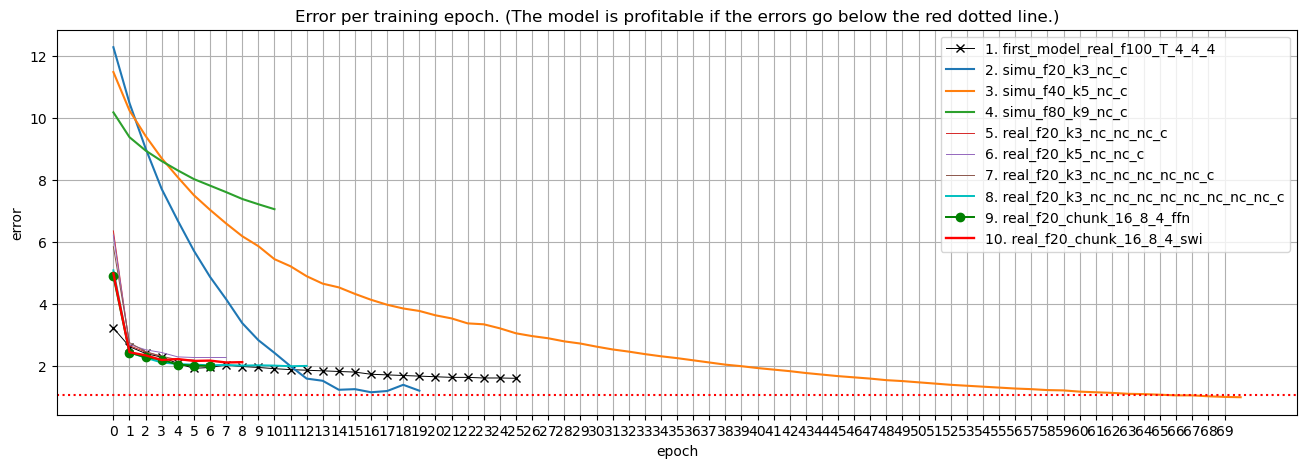

In [32]:
def exp(x, a, b, c):
    return a * np.power(b, x) + c
x = np.array(range(0, 70))
a = 2.4; b = 0.8; c = 0.85
ideal = exp(x, a, b, c)
idle = "Ideal errors = {:.2f} x  {:.2f} ** epoch + {:.2f}".format(a, b, c)

first_model_real_f100_T_4_4_4 = np.array([3.23, 2.63, 2.41, 2.29, 2.09, 1.93, 1.96, 2.04, 1.99, 1.96, 1.92, 1.89, 1.87, 1.85, 1.83, \
    1.81, 1.74, 1.72, 1.70, 1.68, 1.66, 1.64, 1.64, 1.62, 1.62, 1.61])

simu_f20_k3_nc_c = np.array([12.28,10.48,9.02,7.71,6.69,5.72,4.88,4.16,3.39,2.84,2.43,2.00,1.60,1.53,1.24,1.26,1.16,1.20,1.40,1.21])
simu_f40_k5_nc_c = np.array([11.48,10.24,9.42,8.70,8.09,7.51,7.04,6.60,6.19,5.87,5.45,5.22,4.90,4.66,4.54,4.33,4.14,3.98,3.86,3.78,3.64,3.54,3.38,3.35,3.22,3.06,
    2.97,2.90,2.80,2.73,2.63,2.54,2.47,2.39,2.32,2.26,2.19,2.12,2.05,2.00,1.94,1.89,1.84,1.78,1.73,1.68,1.64,1.60,1.55,1.52,1.48,1.44,1.40,1.37,1.34,1.31,1.28,1.26,1.23,1.22,1.18,
    1.16,1.14,1.11,1.10,1.08,1.06,1.06,1.03,1.01,1.00])
    # ,0.79,0.78,0.77,
    # 0.76,0.76,0.75,0.75,0.74,0.73,0.72,0.72,0.72,0.71,0.70,0.70,0.70,0.69,0.68,0.68,0.67,0.68,0.67,0.67,0.66,0.65,0.65,0.65,0.65])
simu_f80_k9_nc_c = np.array([10.18,9.38,8.95,8.61,8.31,8.03,7.82,7.61,7.39,7.22,7.06])
real_f20_k3_nc_nc_nc_c = np.array([6.36, 2.66, 2.46, 2.31])
real_f20_k5_nc_nc_c = np.array([6.22, 2.70, 2.53, 2.44, 2.30, 2.28, 2.28, 2.28])
real_f20_k3_nc_nc_nc_nc_nc_c = np.array([5.85, 2.76, 2.47, 2.32, 2.21, 2.20])
real_f20_k3_nc_nc_nc_nc_nc_nc_nc_nc_c = np.array([5.09, 2.45, 2.27, 2.12, 2.07, 2.05, 2.03, 2.04, 2.02, 2.03, 2.02, 2.00, 2.01])

real_f20_chunk_16_8_4_ffn = np.array([4.90, 2.44, 2.29, 2.21, 2.05, 2.02, 2.01])
real_f20_chunk_16_8_4_swi = np.array([4.99, 2.45, 2.35, 2.20, 2.23, 2.17, 2.18, 2.12, 2.13])

plt.figure(figsize=(16, 5))
# plt.plot(x, ideal, linestyle='-')
# plt.plot(x, worst, linestyle='-', marker='o', label=label_worst)

plt.plot(first_model_real_f100_T_4_4_4, label='1. first_model_real_f100_T_4_4_4', c='k', marker='x', lw=0.7)
plt.plot(simu_f20_k3_nc_c, label='2. simu_f20_k3_nc_c')
plt.plot(simu_f40_k5_nc_c, label='3. simu_f40_k5_nc_c')
plt.plot(simu_f80_k9_nc_c, label='4. simu_f80_k9_nc_c')

plt.plot(real_f20_k3_nc_nc_nc_c, label='5. real_f20_k3_nc_nc_nc_c', lw=0.7)
plt.plot(real_f20_k5_nc_nc_c, label='6. real_f20_k5_nc_nc_c', lw=0.7)
plt.plot(real_f20_k3_nc_nc_nc_nc_nc_c, label='7. real_f20_k3_nc_nc_nc_nc_nc_c', lw=0.7)
plt.plot(real_f20_k3_nc_nc_nc_nc_nc_nc_nc_nc_c, label='8. real_f20_k3_nc_nc_nc_nc_nc_nc_nc_nc_c', c='c', lw=1.4) #, marker='o')

plt.plot(real_f20_chunk_16_8_4_ffn, label='9. real_f20_chunk_16_8_4_ffn', c='g', marker='o', lw=1.4)
plt.plot(real_f20_chunk_16_8_4_swi, label='10. real_f20_chunk_16_8_4_swi', c='r', lw=1.7)

plt.plot()
plt.xticks(x)
plt.xlabel("epoch")
plt.ylabel("error")
plt.title("Error per training epoch. (The model is profitable if the errors go below the red dotted line.)")
plt.legend()
plt.grid(True)

# # Add y-value labels next to markers
# for xi, yi in zip(x, y):
#     plt.text(xi, yi, f"{yi:.2f}", ha='left', va='bottom', fontsize=8)
    
plt.axhline(y=1.06, color='red', linestyle=':', linewidth=1.5, label='y = 1.06 (reference)')
plt.show()

In [1]:
import torch
print(torch.version.cuda)   # should print something like '12.1' or '11.8'

12.1


In [2]:
import torch
import torch.nn as nn
rnn = nn.LSTM(10, 20, 2)
input = torch.randn(5, 3, 10)
h0 = torch.randn(2, 3, 20)
c0 = torch.randn(2, 3, 20)
output, (hn, cn) = rnn(input, (h0, c0))
print(output)

tensor([[[-0.0613, -0.3674, -0.0791, -0.3514, -0.1391,  0.0106,  0.1951,
           0.2921, -0.0614, -0.1751, -0.3043, -0.1046,  0.4130,  0.2147,
           0.2236, -0.5042,  0.2193,  0.3656,  0.3232, -0.1904],
         [ 0.4156, -0.1040, -0.2098, -0.0903, -0.0873,  0.5756, -0.1800,
          -0.1427, -0.0629, -0.0877, -0.0161,  0.2635,  0.4004, -0.1859,
           0.3628,  0.5131, -0.0086, -0.2344, -0.1717, -0.1995],
         [-0.4004,  0.3321, -0.2998, -0.2740, -0.2078, -0.0427, -0.2600,
           0.0713, -0.2303, -0.1991,  0.1075,  0.0829,  0.1126,  0.3934,
          -0.3559,  0.1532, -0.4424,  0.1890,  0.4829,  0.0336]],

        [[-0.0053, -0.3302, -0.0660, -0.3207, -0.1032,  0.0558,  0.0233,
           0.1593, -0.0802, -0.1171, -0.1926, -0.0244,  0.2099,  0.2180,
           0.1497, -0.2330,  0.1961,  0.1989,  0.2809, -0.1397],
         [ 0.2144,  0.0032, -0.0941, -0.1487, -0.1180,  0.3891, -0.0896,
          -0.0517, -0.0355, -0.0431, -0.0210,  0.2139,  0.1797, -0.1126,
        

In [2]:
x = [1,2,3]
print(x[:5])

[1, 2, 3]


In [1]:
import numpy as np

x = np.array([1,2,3,4])
print(x[2: 8])

[3 4]


In [4]:
import re

names = [
    "zeus1.mlp_head.1.weight",
    "zeus1.mlp_head.1.bias",
    "zeus1.mlp_head.2.weight",
    "zeus1.mlp_head.2.bias",
    "zeus2.mlp_head.1.weight",
    "zeus2.mlp_head.1.bias",
    "zeus2.mlp_head.2.weight",
    "zeus2.mlp_head.2.bias",
]

updated_names = []

for name in names:
    # find the number right after "mlp_head." and subtract 1
    new_name = re.sub(r"(mlp_head\.)(\d+)", 
                      lambda m: f"{m.group(1)}{int(m.group(2))-1}", 
                      name)
    updated_names.append(new_name)

print("\n".join(updated_names))

zeus1.mlp_head.0.weight
zeus1.mlp_head.0.bias
zeus1.mlp_head.1.weight
zeus1.mlp_head.1.bias
zeus2.mlp_head.0.weight
zeus2.mlp_head.0.bias
zeus2.mlp_head.1.weight
zeus2.mlp_head.1.bias


In [3]:
import re

names = [
    "zeus1.mlp_head.1.weight",
    "zeus1.mlp_head.1.bias",
    "zeus1.mlp_head.2.weight",
    "zeus1.mlp_head.2.bias",
    "zeus2.mlp_head.1.weight",
    "zeus2.mlp_head.1.bias",
    "zeus2.mlp_head.2.weight",
    "zeus2.mlp_head.2.bias",
]

updated = []

for name in names:
    parts = name.split('.')  # split by dot
    new_parts = []
    for p in parts:
        # if the part is a number, modify it (example: subtract 1)
        if p.isdigit():
            new_parts.append(str(int(p) - 1))
        else:
            new_parts.append(p)
    updated_name = '.'.join(new_parts)
    updated.append(updated_name)

print("\n".join(updated))

zeus1.mlp_head.0.weight
zeus1.mlp_head.0.bias
zeus1.mlp_head.1.weight
zeus1.mlp_head.1.bias
zeus2.mlp_head.0.weight
zeus2.mlp_head.0.bias
zeus2.mlp_head.1.weight
zeus2.mlp_head.1.bias


In [2]:
import re

names = [
    "zeus1.mlp_head.1.weight",
    "zeus1.mlp_head.1.bias",
    "zeus1.mlp_head.2.weight",
    "zeus1.mlp_head.2.bias",
    "zeus2.mlp_head.1.weight",
    "zeus2.mlp_head.1.bias",
    "zeus2.mlp_head.2.weight",
    "zeus2.mlp_head.2.bias",
]

updated = []
for name in names:
    new_name = re.sub(r"(mlp_head\.)(\d+)", 
                      lambda m: f"{m.group(1)}{int(m.group(2))-1}", 
                      name)
    updated.append(new_name)

print("\n".join(updated))

zeus1.mlp_head.0.weight
zeus1.mlp_head.0.bias
zeus1.mlp_head.1.weight
zeus1.mlp_head.1.bias
zeus2.mlp_head.0.weight
zeus2.mlp_head.0.bias
zeus2.mlp_head.1.weight
zeus2.mlp_head.1.bias


In [1]:

names = [
    "zeus1.mlp_head.0.weight",
    "zeus1.mlp_head.0.bias",
    "zeus1.mlp_head.1.weight",
    "zeus1.mlp_head.1.bias",
    "zeus2.mlp_head.0.weight",
    "zeus2.mlp_head.0.bias",
    "zeus2.mlp_head.1.weight",
    "zeus2.mlp_head.1.bias",
]

import re

updated = []
for name in names:
    new_name = re.sub(r"(mlp_head\.)(\d+)", 
                      lambda m: f"{m.group(1)}{int(m.group(2))+1}", 
                      name)
    updated.append(new_name)
    
print("\n".join(updated))
    

zeus1.mlp_head.1.weight
zeus1.mlp_head.1.bias
zeus1.mlp_head.2.weight
zeus1.mlp_head.2.bias
zeus2.mlp_head.1.weight
zeus2.mlp_head.1.bias
zeus2.mlp_head.2.weight
zeus2.mlp_head.2.bias


In [38]:
import torch

def _acquire_device(self):
    if torch.cuda.is_available():
        device_type = 'cuda'
        default_device = torch.device('cuda:0')
        nDevices = torch.cuda.device_count()
    else:
        device_type = 'cpu'
        default_device = torch.device('cpu:0')
        nDevices = torch.cpu.device_count()

    return device_type, nDevices, default_device

In [40]:
t, n, d = _acquire_device(2)

print(t, n, d)

cuda 1 cuda:0


In [13]:
import math
import numpy as np
import matplotlib.pyplot as plt

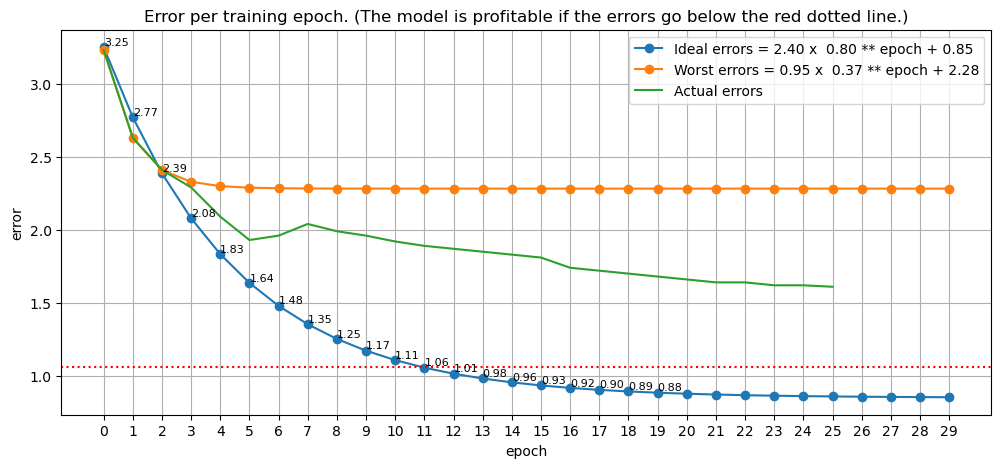

In [33]:
def exp(x, a, b, c):
    return a * np.power(b, x) + c
x = np.array(range(0, 30))
a = 2.4; b = 0.8; c = 0.85
ideal = exp(x, a, b, c)
label_ideal = "Ideal errors = {:.2f} x  {:.2f} ** epoch + {:.2f}".format(a, b, c)

a = 0.947; b = 0.366; c = 2.282
worst = exp(x, a, b, c)
label_worst = "Worst errors = {:.2f} x  {:.2f} ** epoch + {:.2f}".format(a, b, c)
# a = 0.8873; b = 0.5455; c = 2.14
actual = np.array([3.23, 2.63, 2.41, 2.29, 2.09, 1.93, 1.96, 2.04, 1.99, 1.96, 1.92, 1.89, 1.87, 1.85, 1.83, \
    1.81, 1.74, 1.72, 1.70, 1.68, 1.66, 1.64, 1.64, 1.62, 1.62, 1.61])
label_actual = "Actual errors"
# Plot with markers
plt.figure(figsize=(12, 5))
plt.plot(x, ideal, linestyle='-', marker='o', label=label_ideal)
plt.plot(x, worst, linestyle='-', marker='o', label=label_worst)
plt.plot(actual, label=label_actual)
plt.xticks(x)
plt.xlabel("epoch")
plt.ylabel("error")
plt.title("Error per training epoch. (The model is profitable if the errors go below the red dotted line.)")
plt.legend()
plt.grid(True)

# Add y-value labels next to markers
for xi, yi in zip(x, y):
    plt.text(xi, yi, f"{yi:.2f}", ha='left', va='bottom', fontsize=8)
    
plt.axhline(y=1.06, color='red', linestyle=':', linewidth=1.5, label='y = 1.06 (reference)')

plt.show()

In [36]:
import torch
default_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu:0")   # default device. device 0 if default is not changed.
if default_device == "cuda:0":
    nDevices = torch.cuda.device_count()
else:
    nDevices = torch.cpu.device_count()
print(default_device, nDevices)

cuda:0 1


In [ ]:
import torch
_epoch_loss = torch.tensor(3.0)
_epoch_rmses = torch.tensor((2., 3., 4., 5.))
loss = "Loss: {:.4f}".format(_epoch_loss.item())
rmses = "RMSE: " + ", ".join(f"{x:.2f}" for x in _epoch_rmses.ravel().tolist())
display = loss + ', ' + rmses
print(display)

In [ ]:
import cupy as cp

arr = cp.load("file.npy")[:, :, :720, :]
mean = cp.mean(arr, axis=(0, 2, 3))
var  = cp.mean((arr - mean)**2, axis=(0, 2, 3))
std  = cp.sqrt(var)


In [ ]:
import torch
from einops import rearrange
import numpy as np
import os

In [ ]:
x = torch.rand((24, 4, 721, 1440))
path = os.path.join("d:\download", 'test.npz')
np.savez_compressed(path, x)

In [ ]:
load = np.load(path)
x = load[load.files[0]]


In [ ]:
x = torch.rand((24, 4, 721, 1440))
path = os.path.join("d:\download", 'test.npy')
np.save(path, x)

In [ ]:
load = np.load(path)

In [ ]:
raw_rmse = torch.ones((2, 4, 1, 1)) # (B, C, 1, 1)
gamma = torch.ones((2, 4, 6, 8)) # (B, C, H, W)

In [ ]:
def get_curved_scores(raw_rmse: torch.Tensor, gamma: float) -> torch.Tensor:
    # gamma: (B, C, H, W)
    min_rmse = rearrange(torch.tensor((0.1, 0.0, 0.4, 0.4)), 'c -> c 1 1')    # Mike!!! Rough. They come from w&d
    max_rmse = raw_rmse * 1.2   # Mike!!! A rouph assumption

    min_rmse = torch.minimum(min_rmse, raw_rmse)
    eq = (min_rmse == max_rmse)

    amin = torch.minimum(min_rmse, max_rmse)
    amax = torch.maximum(min_rmse, max_rmse)
    den  = (amax - amin)
    norm = (raw_rmse - amin) / torch.clamp(den, min=1e-12)
    norm = torch.where(eq, torch.ones_like(norm), norm)

    return torch.pow(norm, gamma)  # gamma.shape = (B, C, H, W)

In [ ]:
def get_rmse(target: torch.Tensor, prediction: torch.Tensor, dims: tuple) -> torch.Tensor:
    try:
        return ((prediction - target) ** 2).mean(dim=dims).sqrt()
    except:
        return - torch.ones_like(prediction.mean(dim=dims))

In [ ]:
# def loss(self, target, pred, batch_diff, era5_data_vars):
#     # (B,FG,C,H,W), (B,FG,C,H,W), (B, C, H, W), (C,)
target = torch.rand((2, 24, 4, 600, 800)) - 0.5
pred = torch.rand((2, 24, 4, 600, 800)) - 0.5
min_sota_delta = torch.rand((4,))
batch_diff = torch.rand((2, 4, 600, 800))
era5_data_vars = torch.rand((4,))

baseline_rmse = torch.tensor(0.0)               # (,)

rmse = get_rmse(target, pred, dims=(1, 3, 4))    # (B, C)  the-higher-the-worse
improvement = baseline_rmse - rmse  - min_sota_delta   # (B, C)  the-higher-the-better
baseline_improvement = torch.maximum(torch.tensor(0.0), improvement)    # 0.0, (B, C)  the-higher-the-better

gamma = np.power(3.0, batch_diff * 2 - 1)  # (B, C, H, W)
quality_score = get_curved_scores(rearrange(rmse, 'b c -> b c 1 1' ), gamma)       # (B, C, H, W) the-higher-the-worse
baseline_improvement = rearrange(baseline_improvement, 'b c -> b c 1 1')                # 0.0, (B, C, 1, 1)
improvement_score = get_curved_scores(-baseline_improvement, gamma) # 1.0, (B, C, H, W) the-higher-the-worse
reward = (1 - 0.5) * quality_score + 0.5 * improvement_score    # (B, C, H, W)
reward = reward * rearrange(era5_data_vars, 'c -> c 1 1')   # (B, 1, C, H, W) the-higher-the-worse
reward = reward.mean()

# print(reward)
# return reward

In [ ]:
import sys
import os
import numpy as np
import torch
from torch import nn
from tqdm import tqdm

from einops.layers.torch import Rearrange
from einops import rearrange, repeat
from fvcore.nn import FlopCountAnalysis, flop_count_table


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

In [ ]:
sys.path.append(os.path.abspath(os.path.join('..', 'models')))

from Zeus_Trainer import Trainer

In [ ]:
def sample_time_range(self) -> Tuple[pd.Timestamp, pd.Timestamp, int]:
    """
    Sample random start and end times according to the provided ranges.
    """
    num_predict_hours = np.random.randint(*self.predict_sample_range)

        # see visualisation at Zeus/static/era5_start_offset_distribution.png
    if np.random.rand() > self.uniform_start_prob:
        start_offset = min(
            self.start_offset_range[1], # don't overshoot
            np.abs(
                int(np.random.normal(0, self.start_sample_std))
            ) + self.start_offset_range[0]
        )
    else:
        start_offset = int(np.random.uniform(*self.start_offset_range))

    start_timestamp = get_today("h") + pd.Timedelta(hours=start_offset)
    end_timestamp = start_timestamp + pd.Timedelta(hours=num_predict_hours - 1)

    return start_timestamp, end_timestamp, num_predict_hours

In [ ]:
def get_curved_scores(raw_scores: List[float], gamma: float) -> List[float]:
    """
    Given a list of raw float scores (can by any range),
    normalise them to 0-1 scores,
    and apply gamma correction to curve accordingly.

    This function assumes lower is better
    """
    min_score = min(raw_scores)
    max_score = max(raw_scores)

    result = []
    for score in raw_scores:
        if max_score == min_score:
            result.append(1.0) # edge case, avoid division by 0
        else:
            norm_rmse = (max_score - score) / (max_score - min_score)
            result.append(np.power(norm_rmse, gamma)) # apply gamma correction
    
    return result

In [ ]:
def set_rewards(
    output_data: torch.Tensor,
    miners_data: List[MinerData],
    baseline_data: Optional[torch.Tensor],
    difficulty_grid: np.ndarray,
    min_sota_delta: float
) -> List[MinerData]:
    """
    Calculates rewards for miner predictions based on RMSE and relative difficulty.
    NOTE: it is assumed penalties have already been scored and filtered out, 
      if not will do so without scoring those

    Args:
        output_data (torch.Tensor): The ground truth data.
        miners_data (List[MinerData]): List of MinerData objects containing predictions.
        baseline_data (torch.Tensor): OpenMeteo prediction, where additional incentive is awarded to beat this!
        difficulty_grid (np.ndarray): Difficulty grid for each coordinate.

    Returns:
        List[MinerData]: List of MinerData objects with updated rewards and metrics.
    """
    miners_data = [m for m in miners_data if not m.shape_penalty]

    if len(miners_data) == 0:
        return miners_data

    # old challenges have no baseline, use 0 to make it not affect scoring.
    baseline_rmse = 0
    if baseline_data is not None:
        baseline_rmse = rmse(output_data, baseline_data)
        
    avg_difficulty = difficulty_grid.mean()
    # make difficulty [-1, 1], then go between [1/scaler, scaler]
    gamma = np.power(REWARD_DIFFICULTY_SCALER, avg_difficulty * 2 - 1)

    # compute unnormalised scores
    for miner_data in miners_data:
        miner_data.rmse = rmse(output_data, miner_data.prediction)
        improvement = baseline_rmse - miner_data.rmse - min_sota_delta
        miner_data.baseline_improvement = max(0, improvement)

    quality_scores = get_curved_scores([m.rmse for m in miners_data], gamma)
    # negative since curving assumes minimal is the best
    improvement_scores = get_curved_scores([-m.baseline_improvement for m in miners_data], gamma)

    for miner_data, quality, improvement in zip(miners_data, quality_scores, improvement_scores):
        miner_data.reward = (1 - REWARD_IMPROVEMENT_WEIGHT) * quality + REWARD_IMPROVEMENT_WEIGHT * improvement

    return miners_data

In [ ]:
config = {
    # image h w c
    'height': 72,
    'width': 144,
    'channels': 2,
    # video length in and out
    'T1': 1,    # 5 later.
    'MaxT2': 5,
    'FG': 24,   # frames in a frame group
    # patch size
    'patch_size': 8,
    # transformer
    'heads': 8,
    'dim_head': 32,
    'dropout': 0.0,
    'attn_dropout': 0.0,
    'drop_path': 0.0,
    'patch_dim_to_dim' : 1,
    'dim_to_mlp_dim': 2,
    # layers
    'attLayers' : 1,
    'zeusLayers': 6,
}

In [ ]:
trainer = Trainer(config)

In [ ]:
x = torch.rand(1, 24, 2, 72, 144)
output = trainer.model(x)
print(output.shape)  # [B, T, C, H, W]
# # Calculate FLOPs
flops = FlopCountAnalysis(trainer.model, x)
print(f'Number of flops: {flop_count_table(flops)}')
